# Seoul Bike Sharing Demand — Time-Series Data Analysis & Forecasting

**Group assignment** | Task 1 — Time-series Preprocessing and Exploratory Analysis

**Dataset:** Seoul Bike Sharing Demand

**Target:** Hourly `rented_bike_count`; **forecast horizon:** one hour ahead.

### How to run
- **Google Colab:** Upload *this notebook* to Colab, click **Runtime → Run all**, authorize **Google Drive mount**, then **manually upload** `SeoulBikeData.csv` in the file chooser that appears. No dataset is fetched from Kaggle/the internet by this notebook. All data and outputs are automatically written to `MyDrive/Seoul_Bike_Task1`.
- **Local Jupyter / VS Code:** Extract the supplied project ZIP, open `notebooks/Task1_Seoul_Bike_Complete.ipynb`, and run all cells. The bundled dataset at `data/raw/SeoulBikeData.csv` is used automatically, and outputs are written inside the project.

> **Scope:** This notebook completes Task 1 sections A (understand/preprocess), B (five questions, including lags and moving averages), and C (hyperparameter tuning, experiments, forecasting).

**Individual contributions:** Replace the group/member details in `CONTRIBUTIONS.md` before submission. Run this notebook yourself and be ready to explain its methods/results.

### 1. Project setup, Google Drive mounting, and manual dataset upload

The objective is to prepare a reproducible environment and specify where the dataset and all outputs will be stored.

The codes detects whether the notebook is running in Google Colab. In Colab, it mounts your Google Drive, prompts you to manually upload the dataset and copies the uploaded file into `MyDrive/Seoul_Bike_Task1/data/raw/`. In local Jupyter or VS Code, it looks for the dataset in the project's `data/raw/` folder. It then creates separate folders for processed data, charts, tables, trained models, and reports.

The output prints the execution environment, the saved CSV path, the project output folder, and the uploaded file size.

In [ ]:
from pathlib import Path
import os, shutil, json, sys

DATASET_NAME = "SeoulBikeData.csv"
DRIVE_FOLDER_NAME = "Seoul_Bike_Task1"

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # This prompts you to grant access to YOUR Google Drive.
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive") / DRIVE_FOLDER_NAME
    RAW_DIR = PROJECT_DIR / "data" / "raw"
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    print("Please manually select and upload SeoulBikeData.csv from your computer.")
    uploaded = files.upload()  # MANUAL upload: never downloads a dataset from a URL
    if not uploaded:
        raise FileNotFoundError("No file uploaded. Re-run this cell and choose SeoulBikeData.csv.")
    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
    if len(csv_files) != 1:
        raise ValueError("Please upload exactly one CSV file: SeoulBikeData.csv")
    DATASET_PATH = RAW_DIR / DATASET_NAME
    DATASET_PATH.write_bytes(uploaded[csv_files[0]])
else:
    cwd = Path.cwd().resolve()
    options = [cwd, cwd.parent]
    PROJECT_DIR = next((p for p in options if (p / "data" / "raw" / DATASET_NAME).is_file()), None)
    if PROJECT_DIR is None:
        raise FileNotFoundError(
            "Extract the project ZIP and run this notebook from its 'notebooks/' "
            "or project root folder. Expected file: data/raw/SeoulBikeData.csv"
        )
    DATASET_PATH = PROJECT_DIR / "data" / "raw" / DATASET_NAME

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIG_DIR = PROJECT_DIR / "outputs" / "figures"
TABLE_DIR = PROJECT_DIR / "outputs" / "tables"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "report"
for folder in [PROCESSED_DIR, FIG_DIR, TABLE_DIR, MODEL_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Execution:", "Google Colab + Google Drive" if IN_COLAB else "Local / VS Code")
print("Dataset read from:", DATASET_PATH)
print("Results saved automatically to:", PROJECT_DIR)
print("CSV file size:", f"{DATASET_PATH.stat().st_size:,}", "bytes")

Mounted at /content/drive
Please manually select and upload SeoulBikeData.csv from your computer.


Saving SeoulBikeData.csv to SeoulBikeData (1).csv
Execution: Google Colab + Google Drive
Dataset read from: /content/drive/MyDrive/Seoul_Bike_Task1/data/raw/SeoulBikeData.csv
Results saved automatically to: /content/drive/MyDrive/Seoul_Bike_Task1
CSV file size: 604,166 bytes


### 2. Load the CSV and inspect the original dataset

The objective is to confirm that the manually uploaded Seoul Bike Sharing Demand file can be read and understand its initial structure before any modifications.

The code imports Pandas, NumPy, Matplotlib, and Seaborn, configures plotting, and attempts to read the CSV using `utf-8-sig`, `cp1252`, or `latin1` encoding. This accommodates special characters in weather-related column names. It then prints the encoding selected, dataset dimensions, and original column names, and displays the first five observations.

A preview of the raw date, hour, rental count, weather variables, season, holiday, and functioning-day fields. This establishes the data source and initial schema for subsequent analysis.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "axes.titleweight": "bold"})

encoding_used = None
for encoding in ("utf-8-sig", "cp1252", "latin1"):
    try:
        raw = pd.read_csv(DATASET_PATH, encoding=encoding)
        encoding_used = encoding
        break
    except UnicodeDecodeError:
        continue

print("Encoding:", encoding_used)
print("Original dataset shape:", raw.shape)
print("Original columns:", raw.columns.tolist())
display(raw.head(5))

Encoding: cp1252
Original dataset shape: (8760, 14)
Original columns: ['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day']


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


## Understanding and preprocessing the dataset

### 3. Standardize variables, construct timestamps, and audit data quality

The objective is to establish a valid hourly time series and identify problems that could compromise later analysis or forecasting.

The code checks that all 14 expected original columns exist, renames them to consistent snake_case names, parses the date using day/month/year format, combines the date and hour into a single `timestamp`, and sorts all records chronologically. It then checks missing cells, exact duplicate rows, duplicate timestamps, missing hourly intervals, and impossible negative rental counts.

A unique, uninterrupted hourly timestamp is required for correct 1-hour, 24-hour, and 168-hour lags. Missing or invalid records must be investigated before modeling; legitimate **zero-rental** observations are **not** missing data.

What we can expect is a data-quality table, time-range and frequency checks, and two CSV files in `outputs/tables/`: `raw_missing_values.csv` and `data_quality_checks.csv`. The code intentionally stops if major data-quality problems are detected.

In [ ]:
COLUMN_MAP = {
    "Date": "date", "Rented Bike Count": "rented_bike_count", "Hour": "hour",
    "Temperature(°C)": "temperature_c", "Humidity(%)": "humidity_pct",
    "Wind speed (m/s)": "wind_speed_ms", "Visibility (10m)": "visibility_10m",
    "Dew point temperature(°C)": "dew_point_c",
    "Solar Radiation (MJ/m2)": "solar_radiation_mj_m2",
    "Rainfall(mm)": "rainfall_mm", "Snowfall (cm)": "snowfall_cm",
    "Seasons": "season", "Holiday": "holiday", "Functioning Day": "functioning_day",
}
missing_cols = sorted(set(COLUMN_MAP) - set(raw.columns))
if missing_cols:
    raise ValueError(f"The uploaded file is missing required columns: {missing_cols}")

df = raw.rename(columns=COLUMN_MAP).copy()
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y", errors="raise")
df["hour"] = pd.to_numeric(df["hour"], errors="raise").astype(int)
if not df["hour"].between(0, 23).all():
    raise ValueError("Hour must be between 0 and 23.")
df["timestamp"] = df["date"] + pd.to_timedelta(df["hour"], unit="h")
df = df.sort_values("timestamp").reset_index(drop=True)

raw_missing = raw.isna().sum().rename("missing_count")
raw_missing.to_csv(TABLE_DIR / "raw_missing_values.csv", header=True)
raw_duplicate_rows = int(raw.duplicated().sum())
duplicate_timestamps = int(df["timestamp"].duplicated().sum())
expected_hours = pd.date_range(df["timestamp"].min(), df["timestamp"].max(), freq="h")
missing_timestamps = expected_hours.difference(df["timestamp"])
invalid_counts = int((df["rented_bike_count"] < 0).sum())

quality = pd.DataFrame({
    "check": ["Original observations", "Original columns", "Raw missing cells",
              "Exact duplicate rows", "Duplicate timestamps", "Missing hourly timestamps",
              "Negative target values"],
    "result": [len(raw), raw.shape[1], int(raw_missing.sum()), raw_duplicate_rows,
               duplicate_timestamps, len(missing_timestamps), invalid_counts]
})
quality.to_csv(TABLE_DIR / "data_quality_checks.csv", index=False)
display(quality)
print("Time range:", df["timestamp"].min(), "to", df["timestamp"].max())
print("Most frequent timestamp differences:")
display(df["timestamp"].diff().value_counts().head().rename_axis("interval").to_frame("count"))

if duplicate_timestamps or len(missing_timestamps):
    raise ValueError("Irregular/duplicate hourly observations must be resolved before lag modeling.")
if raw_missing.sum() or invalid_counts:
    raise ValueError("Unexpected missing or invalid target/data values: inspect quality table first.")

display(Markdown(
    f"**Data quality interpretation.** The uploaded file covers **{df['timestamp'].min():%d %b %Y %H:%M}** "
    f"to **{df['timestamp'].max():%d %b %Y %H:%M}** at **hourly** granularity "
    f"({len(df):,} records). It has **{int(raw_missing.sum())} missing cells**, "
    f"**{raw_duplicate_rows} duplicate rows**, **{duplicate_timestamps} duplicate timestamps**, "
    f"and **{len(missing_timestamps)} missing hours**. "
    "Because none were found, **no imputation or deduplication was needed**. "
    "Real zero-rental observations were retained; a zero is not missing data."
))

,check,result
0,Original observations,8760
1,Original columns,14
2,Raw missing cells,0
3,Exact duplicate rows,0
4,Duplicate timestamps,0
5,Missing hourly timestamps,0
6,Negative target values,0


Time range: 2017-12-01 00:00:00 to 2018-11-30 23:00:00
Most frequent timestamp differences:


,count
interval,
0 days 01:00:00,8759


**Data quality interpretation.** The uploaded file covers **01 Dec 2017 00:00** to **30 Nov 2018 23:00** at **hourly** granularity (8,760 records). It has **0 missing cells**, **0 duplicate rows**, **0 duplicate timestamps**, and **0 missing hours**. Because none were found, **no imputation or deduplication was needed**. Real zero-rental observations were retained; a zero is not missing data.

### 4. Descriptive statistics and hourly rental distribution

The objective is to summarize the dataset's numerical measurements and understand the distribution of the prediction target, `rented_bike_count`.

The code derives `day_of_week`, `month`, and `is_weekend` from the timestamp; exports a cleaned dataset with an ISO-formatted date; and calculates count, mean, standard deviation, minimum, quartiles, and maximum for each numerical column. It also displays a histogram and horizontal boxplot of hourly rentals, and calculates the average, median, percentage of zero-rental hours, and number of non-functioning observations.

Compare the mean and median to assess skewness; identify the spread and unusually high hourly rental counts; distinguish real zero demand from missing values. Boxplot outliers should not be removed without investigating whether they are valid demand peaks.


Observations: 8,760; distinct days: 365; numerical columns: 13


,count,mean,std,min,25%,50%,75%,max
variable,,,,,,,,
rented_bike_count,8760.0,704.60,645.00,0.0,191.00,504.50,1065.25,3556.00
hour,8760.0,11.50,6.92,0.0,5.75,11.50,17.25,23.00
temperature_c,8760.0,12.88,11.94,-17.8,3.50,13.70,22.50,39.40
humidity_pct,8760.0,58.23,20.36,0.0,42.00,57.00,74.00,98.00
wind_speed_ms,8760.0,1.72,1.04,0.0,0.90,1.50,2.30,7.40
visibility_10m,8760.0,1436.83,608.30,27.0,940.00,1698.00,2000.00,2000.00
dew_point_c,8760.0,4.07,13.06,-30.6,-4.70,5.10,14.80,27.20
solar_radiation_mj_m2,8760.0,0.57,0.87,0.0,0.00,0.01,0.93,3.52
rainfall_mm,8760.0,0.15,1.13,0.0,0.00,0.00,0.00,35.00


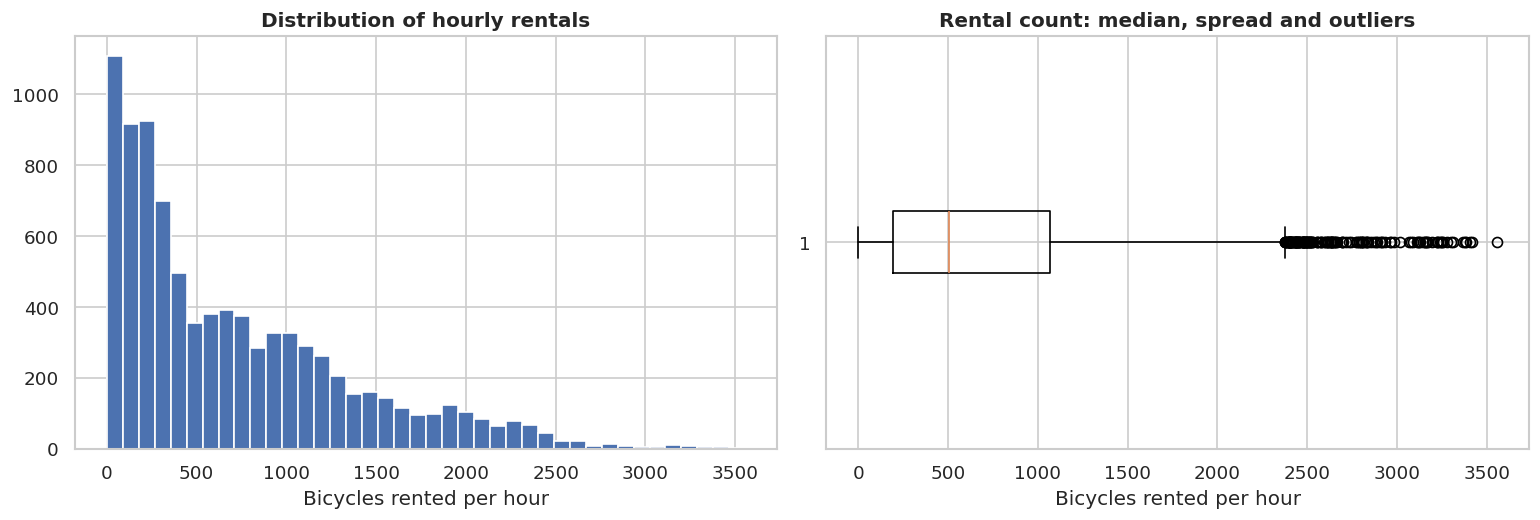

**Distribution interpretation.** Mean rentals = **704.6 per hour**, median = **504.5**. The maximum is **3,556**; **3.4%** of hourly records contain zero rentals. There are **295** observations on non-functioning days, which should be considered when interpreting zeros and model errors.

In [ ]:
df["day_of_week"] = df["timestamp"].dt.dayofweek  # Monday=0
ndays = df["timestamp"].dt.normalize().nunique()
df["month"] = df["timestamp"].dt.month
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

# Use an unambiguous ISO date format in the cleaned file for database teammates.
cleaned = df.copy()
cleaned["date"] = cleaned["date"].dt.strftime("%Y-%m-%d")
cleaned_path = PROCESSED_DIR / "cleaned_seoul_bike.csv"
cleaned.to_csv(cleaned_path, index=False, encoding="utf-8")

numeric_cols = df.select_dtypes(include="number").columns.to_list()
stats = df[numeric_cols].describe().T
stats.index.name = "variable"
stats.to_csv(TABLE_DIR / "descriptive_statistics.csv")
print(f"Observations: {len(df):,}; distinct days: {ndays}; numerical columns: {len(numeric_cols)}")
display(stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df["rented_bike_count"], bins=40)
axes[0].set(title="Distribution of hourly rentals", xlabel="Bicycles rented per hour")
axes[1].boxplot(df["rented_bike_count"], vert=False)
axes[1].set(title="Rental count: median, spread and outliers", xlabel="Bicycles rented per hour")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_distribution.png", bbox_inches="tight", dpi=160)
plt.show()

mean_rental = df["rented_bike_count"].mean()
median_rental = df["rented_bike_count"].median()
zero_rental_pct = (df["rented_bike_count"] == 0).mean() * 100
nonfunctioning_count = (df["functioning_day"] == "No").sum()
display(Markdown(
    f"**Distribution interpretation.** Mean rentals = **{mean_rental:,.1f} per hour**, "
    f"median = **{median_rental:,.1f}**. The maximum is **{df['rented_bike_count'].max():,}**; "
    f"**{zero_rental_pct:.1f}%** of hourly records contain zero rentals. "
    f"There are **{nonfunctioning_count:,}** observations on non-functioning days, "
    "which should be considered when interpreting zeros and model errors."
))

### 5. Seasonal variation, service operation, and weather correlations

The objective is to explore how the distribution of rentals differs across seasons and operating status, and identify numerical variables associated with rental demand.

The code produces two boxplots: hourly rentals by season (`Winter`, `Spring`, `Summer`, `Autumn`) and rentals during functioning versus non-functioning periods. It then computes a **Pearson correlation matrix** for rental counts and eight weather measurements, displayed as an annotated heatmap.

We can interpret by using the median, spread, and outliers to compare groups. Correlation coefficients indicate the direction and strength of **linear association**, not proof of cause and effect. High correlation between two weather variables may indicate overlapping information. Non-functioning periods should be considered when interpreting zero rentals.


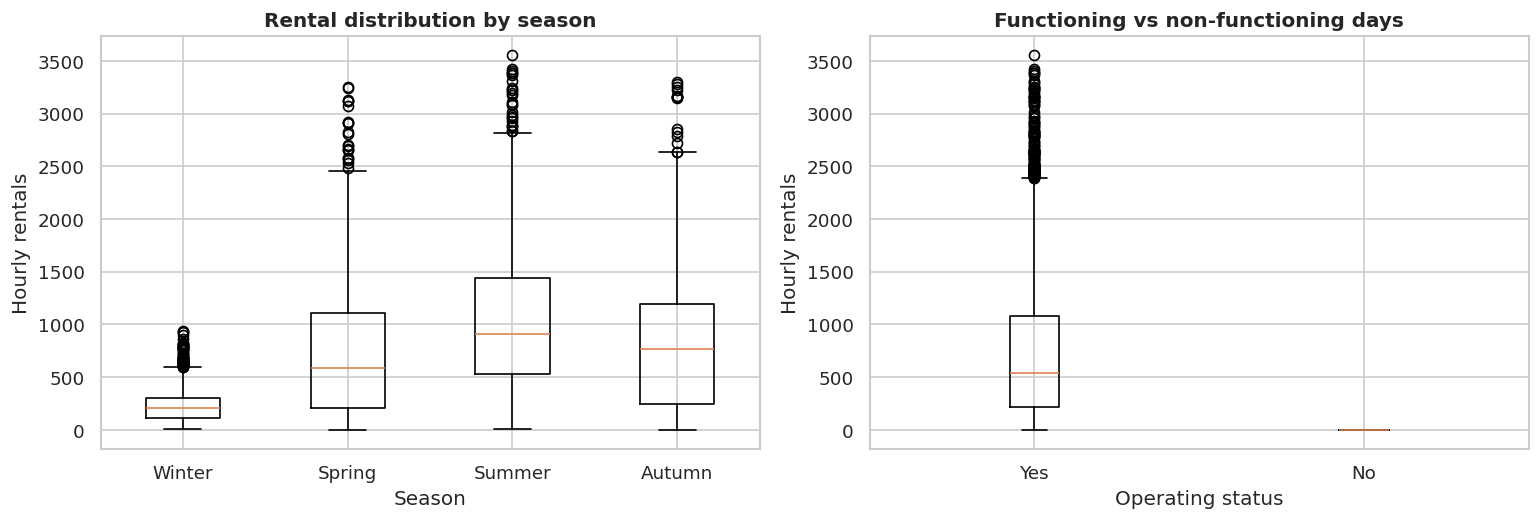

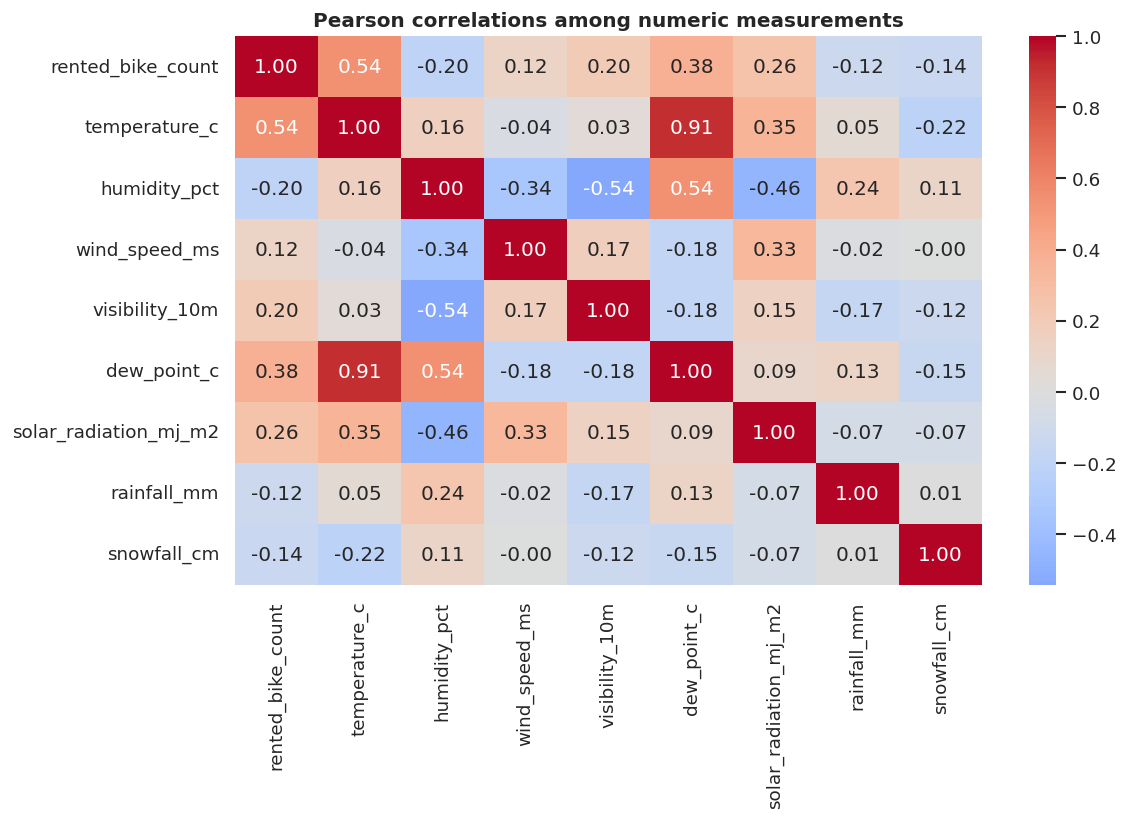

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].boxplot([df.loc[df["season"] == s, "rented_bike_count"] for s in ["Winter", "Spring", "Summer", "Autumn"]], tick_labels=["Winter", "Spring", "Summer", "Autumn"])
axes[0].set(title="Rental distribution by season", xlabel="Season", ylabel="Hourly rentals")
axes[1].boxplot([df.loc[df["functioning_day"] == s, "rented_bike_count"] for s in ["Yes", "No"]], tick_labels=["Yes", "No"])
axes[1].set(title="Functioning vs non-functioning days", xlabel="Operating status", ylabel="Hourly rentals")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_season_and_operating_status.png", bbox_inches="tight", dpi=160)
plt.show()

corr_cols = ["rented_bike_count", "temperature_c", "humidity_pct", "wind_speed_ms",
             "visibility_10m", "dew_point_c", "solar_radiation_mj_m2", "rainfall_mm", "snowfall_cm"]
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Pearson correlations among numeric measurements")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_correlation_heatmap.png", bbox_inches="tight", dpi=160)
plt.show()

## Five analytical questions

### 6. Q1: How does bicycle rental demand change across the year?

Identify within-year demand variation, daily fluctuations, and possible seasonal patterns.

Hourly rental counts are summed to create **daily totals**. A trailing **7-day average of those daily totals** smooths shorter fluctuations. Separately, the mean hourly rental count is calculated for each calendar month. The cell plots the daily series with its moving average and a monthly bar chart.

Identify months with the highest and lowest mean hourly demand and describe how demand changes through winter, spring, summer, and autumn. Because the dataset covers **one year**, these patterns demonstrate **within-year variation**, not a proven long-term trend across several years.


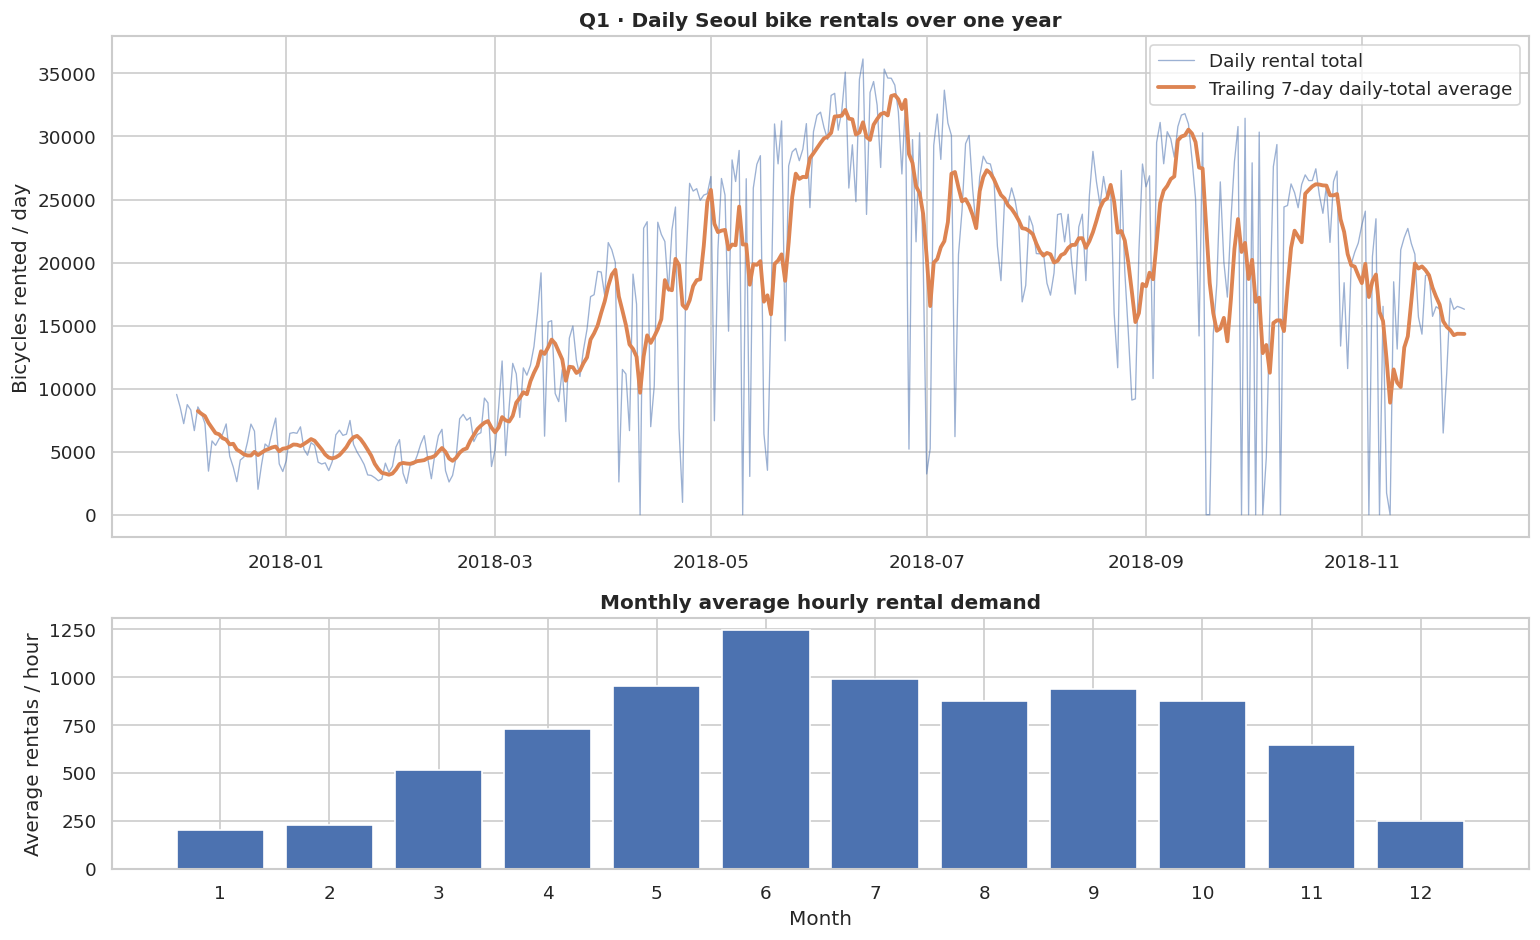

**Q1 finding and interpretation.** Demand is clearly seasonal: the highest mean hourly demand occurs in month 6 (1,245.7 rentals/hour), compared with month 1 (201.6 rentals/hour). Daily totals fluctuate substantially. Because the dataset covers only one year, this should be described as within-year variation, not proof of a multi-year upward or downward trend.

In [ ]:
daily_total = df.set_index("timestamp")["rented_bike_count"].resample("D").sum()
seven_day_mean = daily_total.rolling(7, min_periods=7).mean()
monthly_mean_hourly = df.groupby("month")["rented_bike_count"].mean()

fig, axes = plt.subplots(2, 1, figsize=(13, 8), gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(daily_total.index, daily_total.values, linewidth=0.8, alpha=0.55, label="Daily rental total")
axes[0].plot(seven_day_mean.index, seven_day_mean.values, linewidth=2.3, label="Trailing 7-day daily-total average")
axes[0].set(title="Q1 · Daily Seoul bike rentals over one year", ylabel="Bicycles rented / day")
axes[0].legend()
axes[1].bar(monthly_mean_hourly.index, monthly_mean_hourly.values)
axes[1].set(title="Monthly average hourly rental demand", xlabel="Month", ylabel="Average rentals / hour", xticks=list(range(1,13)))
plt.tight_layout()
plt.savefig(FIG_DIR / "04_Q1_trend_and_months.png", bbox_inches="tight", dpi=160)
plt.show()

q1_high = int(monthly_mean_hourly.idxmax())
q1_low = int(monthly_mean_hourly.idxmin())
q1_text = (f"Demand is clearly seasonal: the highest mean hourly demand occurs in month {q1_high} "
           f"({monthly_mean_hourly.max():,.1f} rentals/hour), compared with month {q1_low} "
           f"({monthly_mean_hourly.min():,.1f} rentals/hour). Daily totals fluctuate substantially. "
           "Because the dataset covers only one year, this should be described as within-year variation, "
           "not proof of a multi-year upward or downward trend.")
display(Markdown("**Q1 finding and interpretation.** " + q1_text))

### 7. Q2: During which hours is bicycle demand highest?

Determine whether rental activity varies systematically by hour of day and identify peak and low-demand periods.

The code groups all observations by the `hour` field (0–23), calculates the **mean rented bike count for each hour**, and displays those means in a bar chart. It automatically identifies and reports the highest- and lowest-demand hours.

Describe the morning, afternoon, evening, and overnight patterns using the computed averages. Commute times can be suggested as a **possible** explanation, but trip-purpose information is not available to prove that interpretation. Hour of day is a potential forecasting input.

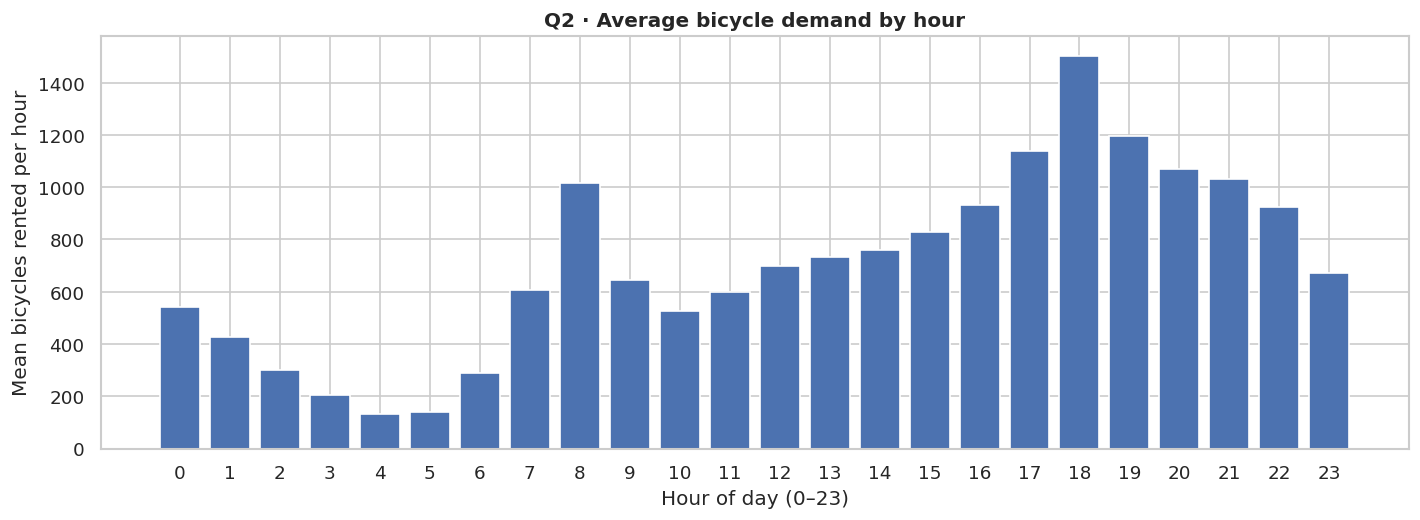

**Q2 finding and interpretation.** Average rental demand peaks at **18:00** (1,502.9 bicycles/hour) and is lowest at **04:00** (132.6 bicycles/hour). This time-of-day difference suggests the hour is an informative forecasting input; commuting may be one possible explanation, but user trip-purpose data would be needed to establish it.

In [ ]:
hourly_means = df.groupby("hour")["rented_bike_count"].mean().sort_index()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(hourly_means.index, hourly_means.values)
ax.set(title="Q2 · Average bicycle demand by hour", xlabel="Hour of day (0–23)",
       ylabel="Mean bicycles rented per hour", xticks=list(range(24)))
plt.tight_layout()
plt.savefig(FIG_DIR / "05_Q2_hourly_rentals.png", bbox_inches="tight", dpi=160)
plt.show()
q2_peak = int(hourly_means.idxmax())
q2_low = int(hourly_means.idxmin())
q2_text = (f"Average rental demand peaks at **{q2_peak:02d}:00** "
           f"({hourly_means.max():,.1f} bicycles/hour) and is lowest at **{q2_low:02d}:00** "
           f"({hourly_means.min():,.1f} bicycles/hour). This time-of-day difference suggests "
           "the hour is an informative forecasting input; commuting may be one possible explanation, "
           "but user trip-purpose data would be needed to establish it.")
display(Markdown("**Q2 finding and interpretation.** " + q2_text))

### 8. Q3: Is temperature associated with bicycle rental demand?

Examine the relationship between air temperature and the hourly number of bicycles rented.

The cell calculates **Pearson's correlation coefficient** between temperature and rentals for (1) all observations and (2) functioning periods only. It creates a scatter plot and groups temperatures into **5°C intervals**, calculating mean rental demand within each interval to check whether the relationship is approximately linear.

Compare the two correlation values and use the temperature-bin chart to identify whether demand increases consistently or levels off at extreme temperatures. Consider operating status and season as possible influences. **Correlation does not establish that temperature causes demand changes.**

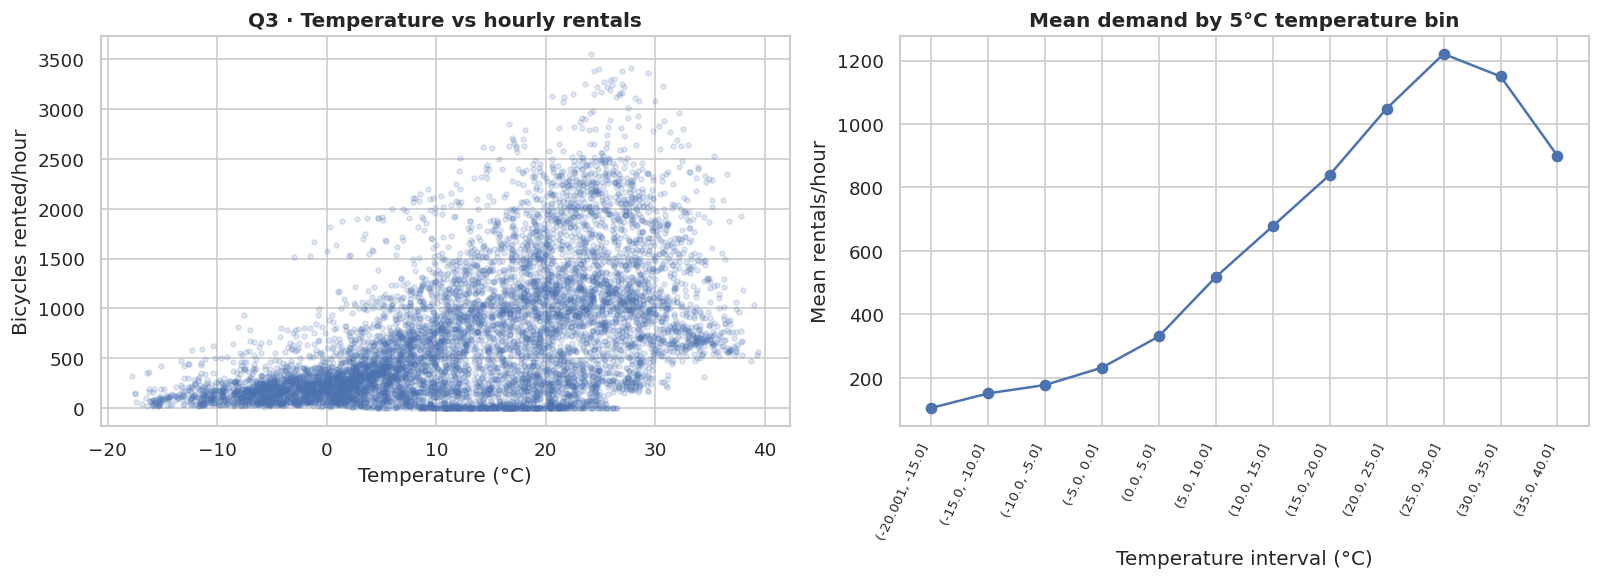

**Q3 finding and interpretation.** Across all hours, Pearson correlation between temperature and hourly rental count is **r = 0.539**; on functioning days only, **r = 0.563**. A positive coefficient indicates an association with increased rentals at warmer temperatures within this dataset, not proof that temperature causes higher demand. The binned chart helps check for nonlinearity and the comparison highlights operating-status confounding.

In [ ]:
temp_r = df["temperature_c"].corr(df["rented_bike_count"])
active = df.loc[df["functioning_day"] == "Yes"]
active_temp_r = active["temperature_c"].corr(active["rented_bike_count"])

temp_bins = pd.cut(df["temperature_c"], bins=np.arange(-20, 46, 5), include_lowest=True)
temp_binned_means = df.groupby(temp_bins, observed=False)["rented_bike_count"].mean().dropna()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
axes[0].scatter(df["temperature_c"], df["rented_bike_count"], s=9, alpha=0.16)
axes[0].set(title="Q3 · Temperature vs hourly rentals", xlabel="Temperature (°C)", ylabel="Bicycles rented/hour")
axes[1].plot(range(len(temp_binned_means)), temp_binned_means.values, marker="o")
axes[1].set_xticks(range(len(temp_binned_means)))
axes[1].set_xticklabels([str(x) for x in temp_binned_means.index], rotation=65, ha="right", fontsize=8)
axes[1].set(title="Mean demand by 5°C temperature bin", xlabel="Temperature interval (°C)", ylabel="Mean rentals/hour")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_Q3_temperature_relationship.png", bbox_inches="tight", dpi=160)
plt.show()
q3_text = (f"Across all hours, Pearson correlation between temperature and hourly rental count is "
           f"**r = {temp_r:.3f}**; on functioning days only, **r = {active_temp_r:.3f}**. "
           "A positive coefficient indicates an association with increased rentals at warmer temperatures "
           "within this dataset, not proof that temperature causes higher demand. The binned chart helps "
           "check for nonlinearity and the comparison highlights operating-status confounding.")
display(Markdown("**Q3 finding and interpretation.** " + q3_text))

### 9. Q4: How strongly is current demand related to previous rentals? (Lagged features)

Test whether past rental counts help explain rental demand at the current hour.

The code indexes the series hourly and constructs historical values using `.shift(1)`, `.shift(24)`, and `.shift(168)`: previous hour, same hour yesterday, and same hour one week earlier. It calculates Pearson correlations between each lag and the current rental count, displays a sampled scatter plot of current versus previous-hour demand, and compares the three correlations in a bar chart.

Compare the strength of hourly, daily, and weekly dependence. These lags use only prior observations and are suitable candidates for predictive features. Their correlation with the target **does not by itself demonstrate forecasting accuracy**.

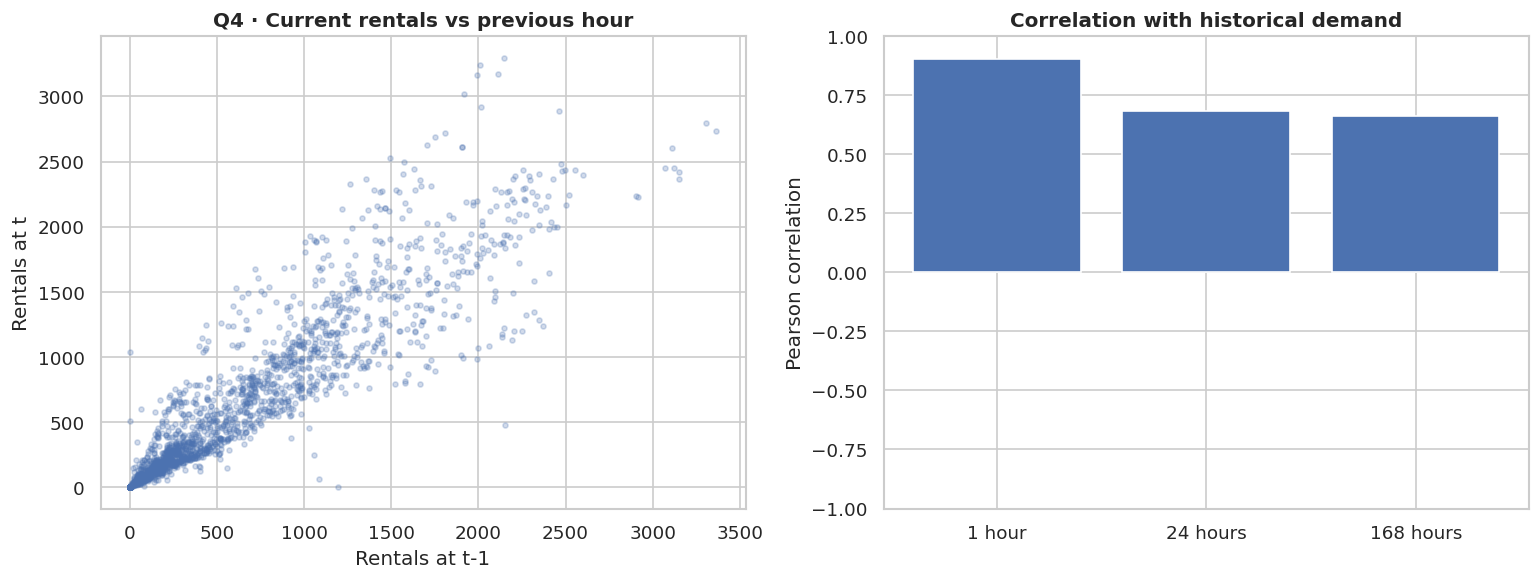

**Q4 finding and interpretation.** Previous rental counts have correlations of **0.903** (1 h), **0.682** (24 h), and **0.661** (168 h) with current rentals. These relationships justify testing lagged features in the forecasting model. Correlation is not a guarantee of out-of-sample predictive accuracy.

In [ ]:
rentals = df.set_index("timestamp")["rented_bike_count"].asfreq("h")
lag_df = pd.DataFrame({"actual": rentals})
lag_df["lag_1h"] = rentals.shift(1)
lag_df["lag_24h"] = rentals.shift(24)
lag_df["lag_168h"] = rentals.shift(168)
lag_correlations = lag_df.corr().loc[["lag_1h", "lag_24h", "lag_168h"], "actual"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
lag_sample = lag_df.dropna().sample(n=min(1800, len(lag_df.dropna())), random_state=42)
axes[0].scatter(lag_sample["lag_1h"], lag_sample["actual"], s=9, alpha=0.25)
axes[0].set(title="Q4 · Current rentals vs previous hour", xlabel="Rentals at t-1", ylabel="Rentals at t")
axes[1].bar(["1 hour", "24 hours", "168 hours"], lag_correlations.values)
axes[1].set(title="Correlation with historical demand", ylabel="Pearson correlation", ylim=(-1, 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "07_Q4_lag_effects.png", bbox_inches="tight", dpi=160)
plt.show()
q4_text = (f"Previous rental counts have correlations of **{lag_correlations['lag_1h']:.3f}** "
           f"(1 h), **{lag_correlations['lag_24h']:.3f}** (24 h), and "
           f"**{lag_correlations['lag_168h']:.3f}** (168 h) with current rentals. "
           "These relationships justify testing lagged features in the forecasting model. "
           "Correlation is not a guarantee of out-of-sample predictive accuracy.")
display(Markdown("**Q4 finding and interpretation.** " + q4_text))

### 10. Q5: What patterns do historical moving averages reveal?

Assess whether rolling averages reduce short-term fluctuations and reveal broader changes in bicycle rental demand.

The code calculates a **24-hour historical moving average** and a **168-hour (7-day) historical moving average**. Both use `shift(1)` before the rolling calculation, so the value at time *t* is based strictly on rental observations **before** *t*. It plots the raw hourly series and both averages over the final 21 days, and compares standard deviations of raw demand and the 24-hour mean across all timestamps with adequate history.

The 24-hour average responds to changes sooner; the 168-hour average is smoother but slower to respond. The standard deviation comparison quantifies smoothing. These past-only rolling values may be useful forecasting features without leaking the current target.

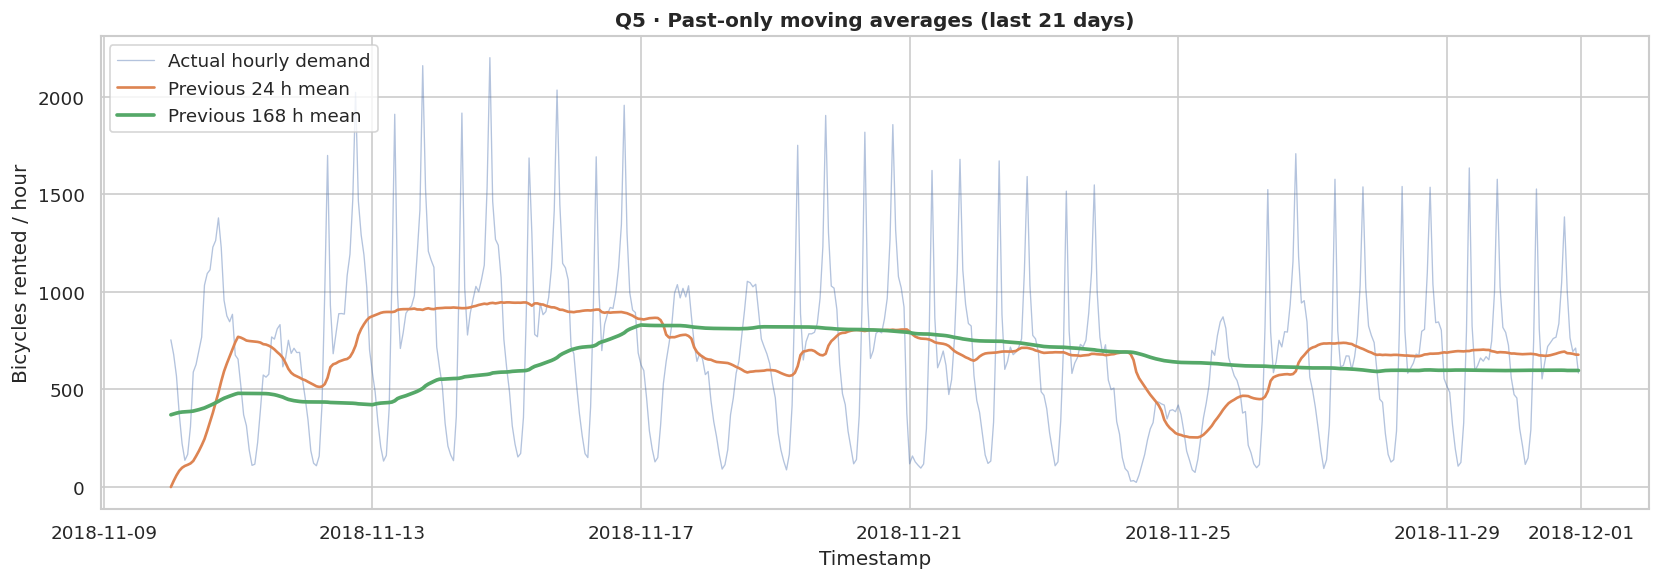

**Q5 finding and interpretation.** The actual hourly series has a standard deviation of **645.6** rentals/hour in rows with a 24 h history; the trailing 24 h mean has a standard deviation of **414.0**. Moving averages smooth hour-to-hour spikes and reveal underlying shifts, but are lagging indicators; the 168 h curve reacts more slowly than the 24 h curve. Past-only rolling averages are candidate prediction features.

In [ ]:
moving = pd.DataFrame({"actual": rentals})
moving["ma_24h_past_only"] = rentals.shift(1).rolling(24, min_periods=24).mean()
moving["ma_168h_past_only"] = rentals.shift(1).rolling(168, min_periods=168).mean()
window_view = moving.tail(21 * 24)
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(window_view.index, window_view["actual"], alpha=0.42, linewidth=0.8, label="Actual hourly demand")
ax.plot(window_view.index, window_view["ma_24h_past_only"], linewidth=1.6, label="Previous 24 h mean")
ax.plot(window_view.index, window_view["ma_168h_past_only"], linewidth=2.2, label="Previous 168 h mean")
ax.set(title="Q5 · Past-only moving averages (last 21 days)", xlabel="Timestamp", ylabel="Bicycles rented / hour")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_Q5_past_moving_averages.png", bbox_inches="tight", dpi=160)
plt.show()
valid_24 = moving.dropna(subset=["ma_24h_past_only"])
q5_text = (f"The actual hourly series has a standard deviation of "
           f"**{valid_24['actual'].std():,.1f}** rentals/hour in rows with a 24 h history; "
           f"the trailing 24 h mean has a standard deviation of **{valid_24['ma_24h_past_only'].std():,.1f}**. "
           "Moving averages smooth hour-to-hour spikes and reveal underlying shifts, but are "
           "lagging indicators; the 168 h curve reacts more slowly than the 24 h curve. "
           "Past-only rolling averages are candidate prediction features.")
display(Markdown("**Q5 finding and interpretation.** " + q5_text))

### Cell 11 — Consolidate and export all five analytical findings

Preserve the research questions, methods, graphs, quantitative findings, and interpretations in a structured format for the written report.

The code creates a `findings` dictionary containing dataset metadata (record count, time range, encoding, and quality checks) and an entry for each analytical question **Q1–Q5**. Every entry records the question, method, generated figure filename, and explanation computed by the preceding cells. It saves the dictionary as readable JSON and displays all five findings in the notebook.

This provides a traceable source for the automatic PDF findings pack, reduces manual transcription errors, and makes the analysis easy to share with the group.


In [ ]:
findings = {
    "dataset": {
        "source": "User-provided Kaggle Seoul Bike Sharing Demand CSV",
        "file": str(DATASET_PATH), "encoding": encoding_used,
        "records": int(len(df)), "raw_columns": int(raw.shape[1]),
        "start": str(df["timestamp"].min()), "end": str(df["timestamp"].max()),
        "frequency": "hourly", "missing_cells": int(raw_missing.sum()),
        "duplicate_rows": raw_duplicate_rows, "duplicate_timestamps": duplicate_timestamps,
        "missing_hours": int(len(missing_timestamps)), "nonfunctioning_hours": int(nonfunctioning_count),
        "zero_rental_percent": round(float(zero_rental_pct), 2),
        "mean_hourly_rentals": round(float(mean_rental), 2),
        "median_hourly_rentals": round(float(median_rental), 2),
    },
    "questions": [
        {"id": "Q1", "question": "How does bike rental demand change across the year?", "method": "Daily total and 7-day average; monthly mean hourly count", "interpretation": q1_text, "figure": "04_Q1_trend_and_months.png"},
        {"id": "Q2", "question": "At what times of day are rentals highest?", "method": "Mean rentals by clock hour", "interpretation": q2_text.replace('**',''), "figure": "05_Q2_hourly_rentals.png"},
        {"id": "Q3", "question": "How is temperature associated with bike rental demand?", "method": "Scatter plot, temperature bins, Pearson correlation", "interpretation": q3_text.replace('**',''), "figure": "06_Q3_temperature_relationship.png"},
        {"id": "Q4", "question": "Do previous rental counts relate to present demand?", "method": "Past 1h/24h/168h lag correlations", "interpretation": q4_text.replace('**',''), "figure": "07_Q4_lag_effects.png"},
        {"id": "Q5", "question": "Do past-only moving averages reveal patterns?", "method": "Previous 24h and 168h moving averages", "interpretation": q5_text.replace('**',''), "figure": "08_Q5_past_moving_averages.png"},
    ]
}
(TABLE_DIR / "analytical_findings.json").write_text(json.dumps(findings, indent=2, ensure_ascii=False), encoding="utf-8")
for q in findings["questions"]:
    display(Markdown(f"**{q['id']}: {q['question']}**  \n*{q['method']}*  \n{q['interpretation']}"))

**Q1: How does bike rental demand change across the year?**  
*Daily total and 7-day average; monthly mean hourly count*  
Demand is clearly seasonal: the highest mean hourly demand occurs in month 6 (1,245.7 rentals/hour), compared with month 1 (201.6 rentals/hour). Daily totals fluctuate substantially. Because the dataset covers only one year, this should be described as within-year variation, not proof of a multi-year upward or downward trend.

**Q2: At what times of day are rentals highest?**  
*Mean rentals by clock hour*  
Average rental demand peaks at 18:00 (1,502.9 bicycles/hour) and is lowest at 04:00 (132.6 bicycles/hour). This time-of-day difference suggests the hour is an informative forecasting input; commuting may be one possible explanation, but user trip-purpose data would be needed to establish it.

**Q3: How is temperature associated with bike rental demand?**  
*Scatter plot, temperature bins, Pearson correlation*  
Across all hours, Pearson correlation between temperature and hourly rental count is r = 0.539; on functioning days only, r = 0.563. A positive coefficient indicates an association with increased rentals at warmer temperatures within this dataset, not proof that temperature causes higher demand. The binned chart helps check for nonlinearity and the comparison highlights operating-status confounding.

**Q4: Do previous rental counts relate to present demand?**  
*Past 1h/24h/168h lag correlations*  
Previous rental counts have correlations of 0.903 (1 h), 0.682 (24 h), and 0.661 (168 h) with current rentals. These relationships justify testing lagged features in the forecasting model. Correlation is not a guarantee of out-of-sample predictive accuracy.

**Q5: Do past-only moving averages reveal patterns?**  
*Previous 24h and 168h moving averages*  
The actual hourly series has a standard deviation of 645.6 rentals/hour in rows with a 24 h history; the trailing 24 h mean has a standard deviation of 414.0. Moving averages smooth hour-to-hour spikes and reveal underlying shifts, but are lagging indicators; the 168 h curve reacts more slowly than the 24 h curve. Past-only rolling averages are candidate prediction features.

## Feature engineering and forecasting model

### 12. Prepare leakage-safe features and chronological train/test partitions

The objective is to predict bicycle rentals for hour *t* using only information available by the end of hour *t−1*.

The code defines **15 input features**: calendar variables (`hour`, `day_of_week`, `month`, `is_weekend`), sine/cosine hour encodings, rental lags (1, 24, 168 hours), historical rolling means (24, 168 hours), historical 24-hour standard deviation, and lagged temperature, humidity, and rainfall. Lags and rolling statistics are computed from previous observations, not the target hour. Rows lacking the complete 168-hour history are excluded **only from the model-ready dataset**.

The model-ready data are divided **chronologically** into the earliest 85% for model development and the final 15% for independent holdout testing. No random shuffling is used.

Model-ready row count, development and test date ranges, input feature names, and a preview of the engineered feature matrix.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from joblib import dump, load
import time

FEATURE_COLUMNS = [
    "hour", "day_of_week", "month", "is_weekend", "hour_sin", "hour_cos",
    "lag_1h", "lag_24h", "lag_168h",
    "rolling_mean_24h", "rolling_mean_168h", "rolling_std_24h",
    "temperature_lag_1h", "humidity_lag_1h", "rainfall_lag_1h"
]

def make_forecasting_features(data):
    """Build one-hour-ahead features, with NO current-target or future-weather leakage."""
    indexed = data.set_index("timestamp").sort_index().asfreq("h").copy()
    indexed["hour"] = indexed.index.hour
    indexed["day_of_week"] = indexed.index.dayofweek
    indexed["month"] = indexed.index.month
    indexed["is_weekend"] = (indexed.index.dayofweek >= 5).astype(int)
    indexed["hour_sin"] = np.sin(2 * np.pi * indexed["hour"] / 24)
    indexed["hour_cos"] = np.cos(2 * np.pi * indexed["hour"] / 24)
    counts = indexed["rented_bike_count"]
    indexed["lag_1h"] = counts.shift(1)
    indexed["lag_24h"] = counts.shift(24)
    indexed["lag_168h"] = counts.shift(168)
    indexed["rolling_mean_24h"] = counts.shift(1).rolling(24, min_periods=24).mean()
    indexed["rolling_mean_168h"] = counts.shift(1).rolling(168, min_periods=168).mean()
    indexed["rolling_std_24h"] = counts.shift(1).rolling(24, min_periods=24).std()
    indexed["temperature_lag_1h"] = indexed["temperature_c"].shift(1)
    indexed["humidity_lag_1h"] = indexed["humidity_pct"].shift(1)
    indexed["rainfall_lag_1h"] = indexed["rainfall_mm"].shift(1)
    return indexed

feature_table = make_forecasting_features(df)
model_data = feature_table.dropna(subset=FEATURE_COLUMNS + ["rented_bike_count"]).copy()
X = model_data[FEATURE_COLUMNS]
y = model_data["rented_bike_count"]
split_idx = int(len(X) * 0.85)
X_dev, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_dev, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
assert X_dev.index.max() < X_test.index.min()

print("Model-ready rows:", len(model_data), "(first 168 hours unavailable for longest lag)")
print("Development:", X_dev.index.min(), "to", X_dev.index.max(), len(X_dev), "rows")
print("Test:", X_test.index.min(), "to", X_test.index.max(), len(X_test), "rows")
print("Input features:", FEATURE_COLUMNS)
display(X.head(3).round(2))

Model-ready rows: 8592 (first 168 hours unavailable for longest lag)
Development: 2017-12-08 00:00:00 to 2018-10-08 06:00:00 7303 rows
Test: 2018-10-08 07:00:00 to 2018-11-30 23:00:00 1289 rows
Input features: ['hour', 'day_of_week', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'lag_1h', 'lag_24h', 'lag_168h', 'rolling_mean_24h', 'rolling_mean_168h', 'rolling_std_24h', 'temperature_lag_1h', 'humidity_lag_1h', 'rainfall_lag_1h']


,hour,day_of_week,month,is_weekend,hour_sin,hour_cos,lag_1h,lag_24h,lag_168h,rolling_mean_24h,rolling_mean_168h,rolling_std_24h,temperature_lag_1h,humidity_lag_1h,rainfall_lag_1h
timestamp,,,,,,,,,,,,,,,
2017-12-08 00:00:00,0,4,12,0,0.00,1.00,259.0,198.0,254.0,356.21,342.49,188.67,-3.2,50.0,0.0
2017-12-08 01:00:00,1,4,12,0,0.26,0.97,233.0,218.0,204.0,357.67,342.36,187.52,-3.5,49.0,0.0
2017-12-08 02:00:00,2,4,12,0,0.50,0.87,230.0,149.0,173.0,358.17,342.52,187.15,-3.7,50.0,0.0


### 13. Hyperparameter tuning with forward-time cross-validation

The objective is to compare Random Forest configurations and select the best using validation data without looking at the final test period.

Three experiments (`RF_1`, `RF_2`, `RF_3`) vary `n_estimators` (number of trees), `max_depth` (tree complexity), and `min_samples_leaf` (minimum samples in each terminal leaf). Each configuration is assessed using **three-fold expanding-window `TimeSeriesSplit`** within the development data. For each fold, predictions are evaluated using **MAE** and **RMSE**; the code also records the standard deviation of fold MAEs and execution time.

Experiments are ranked by **lowest mean cross-validation MAE**; the top configuration is selected for final training. The held-out test set remains untouched during this process.


In [ ]:
EXPERIMENTS = [
    {"experiment": "RF_1", "n_estimators": 80,  "max_depth": 10, "min_samples_leaf": 4},
    {"experiment": "RF_2", "n_estimators": 140, "max_depth": 14, "min_samples_leaf": 2},
    {"experiment": "RF_3", "n_estimators": 180, "max_depth": None, "min_samples_leaf": 2},
]
cv = TimeSeriesSplit(n_splits=3)
rows = []
for params in EXPERIMENTS:
    cv_maes, cv_rmses = [], []
    started = time.perf_counter()
    print("Evaluating", params["experiment"], "...")
    for fold, (train_idx, valid_idx) in enumerate(cv.split(X_dev), start=1):
        regressor = RandomForestRegressor(
            n_estimators=params["n_estimators"],
            max_depth=params["max_depth"],
            min_samples_leaf=params["min_samples_leaf"],
            random_state=42, n_jobs=-1
        )
        regressor.fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
        valid_pred = np.clip(regressor.predict(X_dev.iloc[valid_idx]), 0, None)
        cv_maes.append(mean_absolute_error(y_dev.iloc[valid_idx], valid_pred))
        cv_rmses.append(np.sqrt(mean_squared_error(y_dev.iloc[valid_idx], valid_pred)))
    rows.append({**params,
                 "cv_mae_mean": float(np.mean(cv_maes)),
                 "cv_mae_std": float(np.std(cv_maes)),
                 "cv_rmse_mean": float(np.mean(cv_rmses)),
                 "cv_mae_folds": ", ".join(f"{v:.2f}" for v in cv_maes),
                 "runtime_seconds": round(time.perf_counter()-started, 2)})

experiments = pd.DataFrame(rows).sort_values("cv_mae_mean").reset_index(drop=True)
experiments.to_csv(TABLE_DIR / "experiment_results.csv", index=False)
display(experiments.round(2))
best_row = experiments.iloc[0]
print(f"Best experiment by CV MAE: {best_row['experiment']} ({best_row['cv_mae_mean']:.2f})")

Evaluating RF_1 ...
Evaluating RF_2 ...
Evaluating RF_3 ...


,experiment,n_estimators,max_depth,min_samples_leaf,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_mae_folds,runtime_seconds
0,RF_2,140,14.0,2,185.52,65.22,299.45,"257.33, 199.75, 99.49",8.36
1,RF_3,180,NaN,2,185.97,65.10,300.34,"257.95, 199.70, 100.26",10.92
2,RF_1,80,10.0,4,187.65,65.00,303.23,"260.14, 200.36, 102.46",3.33


Best experiment by CV MAE: RF_2 (185.52)


### 14. Train the selected model and evaluate on unseen observations

The objective is to measure whether the tuned model generalizes to the held-out period and improves on a simple forecasting baseline.

The selected Random Forest is refitted on **all development observations** and predicts the chronological test set. Negative predicted counts are clipped to zero. Its predictions are compared against a **naive previous-hour baseline** (predict the current hour using the previous hour's actual rentals). The evaluation reports **MAE**, **RMSE**, and **R²** for the Random Forest, together with the baseline's MAE and RMSE.

A time-series chart compares observed and predicted rentals over the **first seven test days**. A second chart displays the model's impurity-based feature importances; these indicate model reliance, **not causal effects**.

,Method,Test MAE,Test RMSE,Test R2
0,Naive (previous hour),206.06,313.30,NaN
1,RF_2,69.63,108.06,0.96


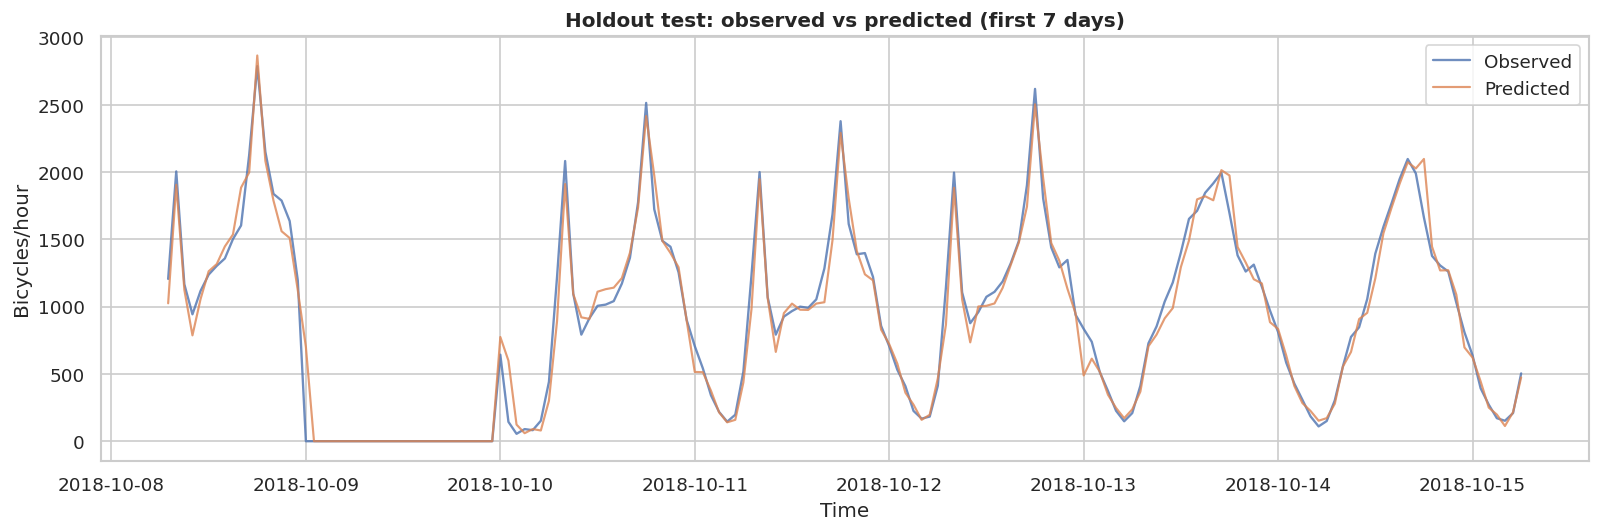

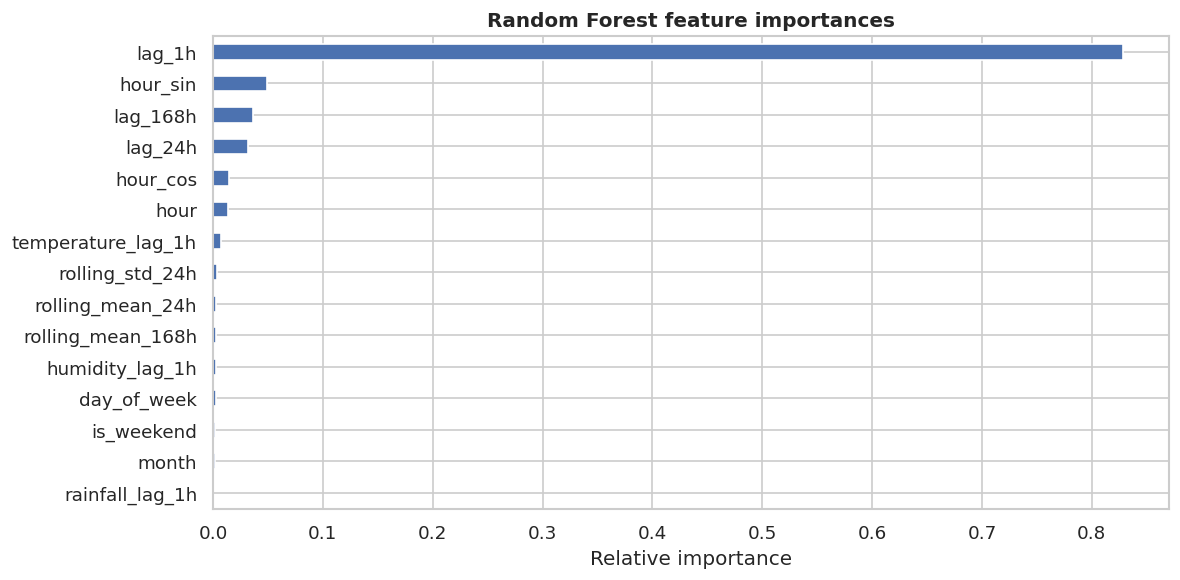

**Model evaluation.** Selected **RF_2** by 3-fold forward-time CV MAE = **185.52**. On the untouched last **1,289 hours**, the model achieved **MAE 69.63**, **RMSE 108.06**, and **R² 0.963**. The previous-hour baseline's MAE was **206.06**. These errors apply to the historical holdout period only; future performance is not guaranteed.

In [ ]:
selected = dict(
    n_estimators=int(best_row["n_estimators"]),
    max_depth=None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"]),
    min_samples_leaf=int(best_row["min_samples_leaf"]),
    random_state=42, n_jobs=-1
)
best_model = RandomForestRegressor(**selected)
best_model.fit(X_dev, y_dev)
y_pred = np.clip(best_model.predict(X_test), 0, None)
naive_pred = X_test["lag_1h"].values  # Baseline: forecast next hour = latest observed rentals

metrics = {
    "selected_experiment": str(best_row["experiment"]),
    "selected_parameters": selected,
    "cv_mae_mean": float(best_row["cv_mae_mean"]),
    "test_rows": int(len(y_test)),
    "test_start": str(y_test.index.min()),
    "test_end": str(y_test.index.max()),
    "test_mae": float(mean_absolute_error(y_test, y_pred)),
    "test_rmse": float(np.sqrt(mean_squared_error(y_test, y_pred))),
    "test_r2": float(r2_score(y_test, y_pred)),
    "baseline_lag1_mae": float(mean_absolute_error(y_test, naive_pred)),
    "baseline_lag1_rmse": float(np.sqrt(mean_squared_error(y_test, naive_pred))),
}
(TABLE_DIR / "model_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
result_table = pd.DataFrame([
    {"Method": "Naive (previous hour)", "Test MAE": metrics["baseline_lag1_mae"],
     "Test RMSE": metrics["baseline_lag1_rmse"], "Test R2": np.nan},
    {"Method": str(best_row["experiment"]), "Test MAE": metrics["test_mae"],
     "Test RMSE": metrics["test_rmse"], "Test R2": metrics["test_r2"]}
])
display(result_table.round(2))

test_predictions = pd.DataFrame({"timestamp": y_test.index, "actual": y_test.values,
                                  "predicted": y_pred, "naive_previous_hour": naive_pred})
test_predictions.to_csv(TABLE_DIR / "test_predictions.csv", index=False)

fig, ax = plt.subplots(figsize=(13.5, 4.6))
plot_n = min(168, len(test_predictions))
ax.plot(test_predictions["timestamp"].iloc[:plot_n], test_predictions["actual"].iloc[:plot_n],
        label="Observed", alpha=0.8, linewidth=1.4)
ax.plot(test_predictions["timestamp"].iloc[:plot_n], test_predictions["predicted"].iloc[:plot_n],
        label="Predicted", alpha=0.8, linewidth=1.3)
ax.set(title="Holdout test: observed vs predicted (first 7 days)", xlabel="Time", ylabel="Bicycles/hour")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "09_holdout_predictions.png", bbox_inches="tight", dpi=160)
plt.show()

importance = (pd.Series(best_model.feature_importances_, index=FEATURE_COLUMNS)
              .sort_values(ascending=True))
fig, ax = plt.subplots(figsize=(10, 5))
importance.plot.barh(ax=ax)
ax.set(title="Random Forest feature importances", xlabel="Relative importance")
plt.tight_layout()
plt.savefig(FIG_DIR / "10_feature_importance.png", bbox_inches="tight", dpi=160)
plt.show()

display(Markdown(
    f"**Model evaluation.** Selected **{metrics['selected_experiment']}** by "
    f"3-fold forward-time CV MAE = **{metrics['cv_mae_mean']:.2f}**. On the untouched "
    f"last **{metrics['test_rows']:,} hours**, the model achieved "
    f"**MAE {metrics['test_mae']:.2f}**, **RMSE {metrics['test_rmse']:.2f}**, "
    f"and **R² {metrics['test_r2']:.3f}**. The previous-hour baseline's MAE was "
    f"**{metrics['baseline_lag1_mae']:.2f}**. These errors apply to the historical "
    "holdout period only; future performance is not guaranteed."
))

### 15. Save and reload the final trained model

The objective is to make the trained model reusable by the teammate building the prediction and API integration components.

The code creates a Joblib **model bundle** containing the fitted Random Forest, the exact ordered list of 15 input features, the 1-hour forecasting horizon, selected hyperparameters, the target field name, and the last development-training timestamp. It saves the bundle to the `models/` directory, reloads it, and verifies that the recorded input features match the training configuration.

Prediction-time features must be created with the **same formulas and column order** used in training. The model file stores the fitted estimator and metadata but does not independently generate lagged or moving-average features.

In [ ]:
artifact_path = MODEL_DIR / "seoul_bike_rf_one_hour.joblib"
model_bundle = {
    "model": best_model,
    "feature_columns": FEATURE_COLUMNS,
    "forecast_horizon_hours": 1,
    "hyperparameters": selected,
    "training_target": "rented_bike_count",
    "last_training_timestamp": str(X_dev.index.max()),
}
dump(model_bundle, artifact_path)
loaded_bundle = load(artifact_path)
assert loaded_bundle["feature_columns"] == FEATURE_COLUMNS
print("Saved model bundle:", artifact_path)
print("Saved cleaned CSV:", cleaned_path)
print("Model artifact size:", f"{artifact_path.stat().st_size/1024/1024:.2f} MB")

Saved model bundle: /content/drive/MyDrive/Seoul_Bike_Task1/models/seoul_bike_rf_one_hour.joblib
Saved cleaned CSV: /content/drive/MyDrive/Seoul_Bike_Task1/data/processed/cleaned_seoul_bike.csv
Model artifact size: 27.05 MB


### 16. Demonstrate an illustrative next-hour forecast

The objective is to check that the saved model can produce a forecast for the hour immediately after the dataset's last historical observation.

The `forecast_next_hour` function checks for at least **168 consecutive hourly records** and no timestamp gaps, calculates the next timestamp, creates the same 15 model inputs from the available historical rentals and weather, orders features according to the saved bundle, and calls the reloaded model to predict a **nonnegative** bicycle count. It prints the prediction and the feature row used.

Because the supplied dataset ends in **November 2018**, the next-hour result is an **illustrative historical forecast**, not a prediction for the present date. The future target value is not provided, so this single prediction cannot be independently scored.

In [ ]:
def forecast_next_hour(history, bundle):
    """One-step forecast from historical observations already known at prediction time."""
    h = history.sort_values("timestamp").reset_index(drop=True)
    if len(h) < 168:
        raise ValueError("At least 168 consecutive historical hourly observations required.")
    gaps = h["timestamp"].diff().iloc[1:]
    if not gaps.eq(pd.Timedelta(hours=1)).all():
        raise ValueError("History must have continuous hourly timestamps for positional lags.")
    next_time = h["timestamp"].iloc[-1] + pd.Timedelta(hours=1)
    yhist = h["rented_bike_count"].astype(float)
    feature = {
        "hour": next_time.hour,
        "day_of_week": next_time.dayofweek,
        "month": next_time.month,
        "is_weekend": int(next_time.dayofweek >= 5),
        "hour_sin": float(np.sin(2 * np.pi * next_time.hour / 24)),
        "hour_cos": float(np.cos(2 * np.pi * next_time.hour / 24)),
        "lag_1h": float(yhist.iloc[-1]),
        "lag_24h": float(yhist.iloc[-24]),
        "lag_168h": float(yhist.iloc[-168]),
        "rolling_mean_24h": float(yhist.iloc[-24:].mean()),
        "rolling_mean_168h": float(yhist.iloc[-168:].mean()),
        "rolling_std_24h": float(yhist.iloc[-24:].std()),
        "temperature_lag_1h": float(h["temperature_c"].iloc[-1]),
        "humidity_lag_1h": float(h["humidity_pct"].iloc[-1]),
        "rainfall_lag_1h": float(h["rainfall_mm"].iloc[-1]),
    }
    one_row = pd.DataFrame([feature], columns=bundle["feature_columns"])
    prediction = float(np.clip(bundle["model"].predict(one_row)[0], 0, None))
    return next_time, prediction, one_row

next_timestamp, next_prediction, inference_features = forecast_next_hour(df, loaded_bundle)
example = {"forecast_timestamp": str(next_timestamp),
           "predicted_rented_bike_count": round(next_prediction, 2),
           "note": "One-hour forecast after final historical 2018 observation; illustrative."}
(TABLE_DIR / "next_hour_forecast.json").write_text(json.dumps(example, indent=2), encoding="utf-8")
print(f"Next historical timestamp: {next_timestamp:%Y-%m-%d %H:%M}")
print(f"Predicted number of bikes rented: {next_prediction:.1f}")
print("Features used (first/only forecast row):")
display(inference_features.round(2))

Next historical timestamp: 2018-12-01 00:00
Predicted number of bikes rented: 430.4
Features used (first/only forecast row):


,hour,day_of_week,month,is_weekend,hour_sin,hour_cos,lag_1h,lag_24h,lag_168h,rolling_mean_24h,rolling_mean_168h,rolling_std_24h,temperature_lag_1h,humidity_lag_1h,rainfall_lag_1h
0,0,5,12,1,0.0,1.0,584.0,474.0,499.0,679.04,597.48,346.25,1.9,43.0,0.0


## Final checks

### 17. Validate required outputs and show saved files

The objective is to verify that the essential deliverables for Task 1A, 1B, and 1C exist before preparing the group submission.

The code checks that all five analytical-question graphs exist, that `experiment_results.csv`, the trained Joblib model, and the cleaned CSV have been saved, and that five analytical questions and at least two experiments were recorded. If all assertions pass, it prints a success message and lists every PNG figure and every table/JSON output together with the project output folder.

The notebook has generated the core analysis, experiment, and model files. This is a **file-existence and consistency check**, not a substitute for visually reviewing every chart or verifying every PDF page.

In [ ]:
from collections import Counter
figures_created = sorted(p.name for p in FIG_DIR.glob("*.png"))
required = ["04_Q1_trend_and_months.png", "05_Q2_hourly_rentals.png",
            "06_Q3_temperature_relationship.png", "07_Q4_lag_effects.png",
            "08_Q5_past_moving_averages.png"]
assert all(name in figures_created for name in required)
assert (TABLE_DIR / "experiment_results.csv").is_file()
assert (MODEL_DIR / "seoul_bike_rf_one_hour.joblib").is_file()
assert cleaned_path.is_file()
assert len(findings["questions"]) == 5
assert len(experiments) >= 2
print("SUCCESS — Task 1 A+B+C completed.")
print("\nSaved figures:")
for name in figures_created: print("  -", name)
print("\nGenerated tables and JSON:")
for p in sorted(TABLE_DIR.iterdir()): print("  -", p.name)
print("\nOutput folder:", PROJECT_DIR)
if IN_COLAB:
    print("Your saved files are in Google Drive: MyDrive /", DRIVE_FOLDER_NAME)
else:
    print("Local project outputs are in:", PROJECT_DIR)

SUCCESS — Task 1 A+B+C completed.

Saved figures:
  - 01_target_distribution.png
  - 02_season_and_operating_status.png
  - 03_correlation_heatmap.png
  - 04_Q1_trend_and_months.png
  - 05_Q2_hourly_rentals.png
  - 06_Q3_temperature_relationship.png
  - 07_Q4_lag_effects.png
  - 08_Q5_past_moving_averages.png
  - 09_holdout_predictions.png
  - 10_feature_importance.png

Generated tables and JSON:
  - analytical_findings.json
  - data_quality_checks.csv
  - descriptive_statistics.csv
  - experiment_results.csv
  - model_metrics.json
  - next_hour_forecast.json
  - raw_missing_values.csv
  - test_predictions.csv

Output folder: /content/drive/MyDrive/Seoul_Bike_Task1
Your saved files are in Google Drive: MyDrive / Seoul_Bike_Task1


### 18. Automatically generate the PDF charts-and-findings supplement

The objective is to assemble the five analytical-question results into a PDF that can support the final written assignment report.

The code uses Matplotlib's `PdfPages` to generate a cover page and then **one page for each question Q1–Q5**. Every question page includes the question title, analysis method, saved visualization, and corresponding interpretation drawn from `analytical_findings.json`-equivalent in-memory results. The PDF is written directly into the project's `report/` folder, which is on **Google Drive when running in Colab**.

In [ ]:
from matplotlib.backends.backend_pdf import PdfPages
import textwrap

pdf_output = REPORT_DIR / "Task1_Auto_Charts_and_Findings.pdf"
with PdfPages(pdf_output) as report_pdf:
    cover = plt.figure(figsize=(8.27, 11.69))
    cover.text(0.10, 0.89, "SEOUL BIKE SHARING DEMAND", fontsize=20, weight="bold")
    cover.text(0.10, 0.84, "Task 1 · Time-series analysis and forecasting", fontsize=13)
    cover.text(0.10, 0.76, f"Dataset: {len(df):,} hourly observations", fontsize=11)
    cover.text(0.10, 0.72, f"Period: {df['timestamp'].min():%d %b %Y} – {df['timestamp'].max():%d %b %Y}", fontsize=11)
    cover.text(0.10, 0.68, f"Data issues: {int(raw_missing.sum())} missing cells / {duplicate_timestamps} duplicate timestamps", fontsize=11)
    cover.text(0.10, 0.62, f"Selected model: {metrics['selected_experiment']}", fontsize=11)
    cover.text(0.10, 0.58, f"Historical test MAE: {metrics['test_mae']:.2f} bicycles/hour", fontsize=11)
    cover.text(0.10, 0.16, "Based only on the manually uploaded CSV. Task 1 only.", fontsize=10)
    cover.text(0.10, 0.12, "Add member names and integrate group tasks before final submission.", fontsize=10)
    report_pdf.savefig(cover)
    plt.close(cover)
    for q in findings['questions']:
        page = plt.figure(figsize=(8.27, 11.69))
        page.text(0.075, 0.94, f"{q['id']} · {q['question']}", fontsize=13, weight="bold")
        page.text(0.075, 0.90, "Method: " + q['method'], fontsize=9)
        panel = page.add_axes([0.06, 0.33, 0.88, 0.51])
        panel.imshow(plt.imread(FIG_DIR / q['figure']))
        panel.axis('off')
        summary = textwrap.fill(q['interpretation'].replace('**', ''), width=90)
        page.text(0.075, 0.27, summary, fontsize=9.2, va='top', linespacing=1.5)
        page.text(0.075, 0.06, "Seoul Bike Sharing Demand · Task 1", fontsize=8)
        report_pdf.savefig(page)
        plt.close(page)
print("PDF findings pack saved automatically to:", pdf_output)
print("Drive folder:" if IN_COLAB else "Local folder:", REPORT_DIR)

PDF findings pack saved automatically to: /content/drive/MyDrive/Seoul_Bike_Task1/report/Task1_Auto_Charts_and_Findings.pdf
Drive folder: /content/drive/MyDrive/Seoul_Bike_Task1/report
